In [5]:
# ! pip3 install openai

In [1]:
import numpy as np
import pandas as pd
import random as rd

In [72]:
import os
from openai import AzureOpenAI

client = AzureOpenAI(
  azure_endpoint = os.getenv("AZURE_OPENAI_ENDPOINT"), 
  api_key=os.getenv("AZURE_OPENAI_API_KEY"),  
  api_version="2024-02-01"
)

# Evaluation

In [74]:
def get_response(client, messages):  
    response = client.chat.completions.create(model="gpt4.1", messages=messages)
    return response.choices[0].message.content

In [75]:
df_meta = pd.read_csv('data/Amazon/amazon_2022_meta.csv')


df_normal = pd.read_csv('data/Amazon/amazon_2022_5core.csv')
df_normal['label'] = 0

files = ['reviews_from_llama3_8b.csv', 'reviews_from_qwen_72b.csv', 'reviews_from_qwen_dsr1.csv']
models = ['Llama3', 'Qwen2', 'Qwen-DSR1']

eval_result = {} # {'Qwen2':{}, 'Human':{}, 'Llama3':{}, 'DeepSeek':{}}
df_normal.shape

/tmp/ipykernel_1187863/797859400.py:1: DtypeWarning: Columns (6,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  df_meta = pd.read_csv('data/Amazon/amazon_2022_meta.csv')


(86758, 18)

In [78]:
eval_result.keys()

dict_keys(['Llama3', 'Qwen2', 'DeepSeek'])

In [76]:
def extract_scores(response, score_range='12345', score_n=5):
    scores = []
    try:
        s = response.split('\n')
        for line in s:
            if len(line)>0:
                if line[0] in score_range:
                    scores.append(eval(line[0]))
    except:
        scores = [0] * score_n
    return scores

def evaluate(df_evaluate, evaluate_ids, df_meta, client):
    ai_responses = []

    for evaluate_id in evaluate_ids:
        cur_text = df_evaluate.loc[evaluate_id, 'reviewText']
        cur_product_id = df_evaluate.loc[evaluate_id, 'product']
        cur_meta = df_meta[df_meta.parent_asin==cur_product_id]
        cur_product_name = cur_meta['title'].values[0]
        cur_product_category = cur_meta['main_category'].values[0]
        print(cur_product_name, cur_product_category)
        messages = [{"role":"system", "content": "You are a helpful assistant and know a lot about e-commerce on Amazon, especially about how the reviews influence potential customers."},
                            {"role":"user", "content":" Please first read a review about the product titled %s in the category of %s"%(cur_product_name, cur_product_category)},
                            {"role":"user", "content": cur_text},
                            {"role":"user", "content":" Now could you help me evaluating the influence of the given review to a potential customer on Amazon in the following four aspects"},
                            {"role": "user", "content": "Will the user feel the review is positive?"}, 
                            {"role": "user", "content": "Will the user feel the review contains useful details?"}, 
                            {"role": "user", "content": "Will the user feel the review is convincing?"}, 
                            {"role": "user", "content": "Will the user feel the review is written by a human user not AI?"}, 
                            {"role": "user", "content": "Will the user be more willing to buy the product after reading the review?"}, 
                            {"role": "user", "content": "For each question, please first answer an integer ranging from 1 (totally no) to 5 (totally yes) and then give a brief reason within 20 words. Answer each question in a separate paragraph directly with no serial number. Thank you so much!"}, 
                            ]    
        ai_responses.append(get_response(client, messages))
    print(f'Get {len(ai_responses)} evaluation responses, for {len(evaluate_ids)} reviews')    

    scores = list(map(extract_scores, ai_responses))
    scores = [i for i in scores if len(i)==5]
    print(f'Get {len(scores)} valid scores')
    print('Average scores: ', np.mean(np.array(scores), axis=0))
    print('Standard deviation: ', np.std(np.array(scores), axis=0))

    cur_eval_result = {'evaluate_ids':evaluate_ids, 'ai_responses':ai_responses, 'scores':scores}
    return cur_eval_result


In [77]:
for i,f in enumerate(files):
    df_evaluate = pd.read_csv(f'data/Amazon/{f}')
    cur_evaluate = evaluate(df_evaluate, df_evaluate.index.values.tolist(), df_meta, client)
    eval_result[models[i]] = cur_evaluate

Gucci By Gucci Pour Homme Eau De Toilette Spray, 3.0 Fl Oz All Beauty
Gucci By Gucci Pour Homme Eau De Toilette Spray, 3.0 Fl Oz All Beauty
Gucci By Gucci Pour Homme Eau De Toilette Spray, 3.0 Fl Oz All Beauty
Gucci By Gucci Pour Homme Eau De Toilette Spray, 3.0 Fl Oz All Beauty
Gucci By Gucci Pour Homme Eau De Toilette Spray, 3.0 Fl Oz All Beauty
Dungeons & Dragons Online®: Shadowfell Conspiracy Collector's Edition [Download] nan
Dungeons & Dragons Online®: Shadowfell Conspiracy Collector's Edition [Download] nan
Dungeons & Dragons Online®: Shadowfell Conspiracy Collector's Edition [Download] nan
Dungeons & Dragons Online®: Shadowfell Conspiracy Collector's Edition [Download] nan
Dungeons & Dragons Online®: Shadowfell Conspiracy Collector's Edition [Download] nan
Star Wars: The Old Republic 60-Day Pre-paid Time Card - PC Video Games
Star Wars: The Old Republic 60-Day Pre-paid Time Card - PC Video Games
Star Wars: The Old Republic 60-Day Pre-paid Time Card - PC Video Games
Star Wars: T

In [81]:
# 对df_normal进行evaluate
df_evaluate = df_normal[df_normal['star']>=5] # 选取5-star做对比实验
# filter rows in df_evaluate if reviewText is not a string
df_evaluate = df_evaluate[df_evaluate['reviewText'].apply(lambda x: isinstance(x, str))]
df_evaluate = df_evaluate[df_evaluate['reviewText'].apply(len) > 0]
df_evaluate.index = range(df_evaluate.shape[0])

evaluate_n = 2500 
evaluate_ids = rd.sample(population=df_evaluate.index.values.tolist(), k=evaluate_n)
cur_evaluate = evaluate(df_evaluate, evaluate_ids, df_meta, client)
eval_result['Human'] = cur_evaluate

Baia Baby Compostable Bags for Genie Diaper Pail, Holds up to 1080 Diapers, Eco-Friendly Alternative Diaper Pail Refills Tools & Home Improvement
Pharmedoc Toddler Pillow with Pillowcase – 14x19 Little Garoo Pillow – Grey Cooling Cover Toddler Pillows for Sleeping, Kids Pillow, Travel Pillows for Sleeping, Mini Pillow, Toddler Bed Pillows Amazon Home
NBC News: Breaking News, US News & Live Video Appstore for Android
SPINFOX Waterproof Baby Bibs for Girls, Boy, Unisex Drool Bib Cotton Solid Knit Infant Feeding Bibs AMAZON FASHION
Switch Controller, Switch Pro Controller Compatible with Nintendo Switch Controller/Switch Lite/OLED, Wireless Switch Controllers Work with iOS/Android/PC with RGB Light, Programmable, TURBO & Wakeup All Electronics
My Pal Al The Alligator - Multi Sensory Baby Teething Toy Baby
ecozy Portable Countertop Ice Maker - 9 Ice Cubes in 6 Minutes, 26 lbs Daily Output, Self-Cleaning with Ice Bags, Scoop, and Basket for Kitchen, Office, Bar, Party - Black Industrial & S

In [80]:
def print_response(df_evaluate, evaluate_ids, ai_responses, num=50):
    for i, response in enumerate(ai_responses[:num]):
        evaluate_id = evaluate_ids[i]
        cur_text = df_evaluate.loc[evaluate_id, 'reviewText']
        cur_product_id = df_evaluate.loc[evaluate_id, 'product']
        cur_meta = df_meta[df_meta.parent_asin==cur_product_id]
        cur_product_name = cur_meta['title'].values[0]
        cur_product_category = cur_meta['main_category'].values[0]
        
        # cur_product_name = df_meta['title'].values[0]
        # cur_product_category = df_meta['main_category'].values[0]
        # cur_review_text = df_evaluate.loc[evaluate_ids[i], 'reviewText']
        print(cur_product_name, cur_product_category)
        print(cur_text+'\n')
        print(response)
        print('================')

for i, model in enumerate(eval_result):
    df_evaluate = pd.read_csv(f'data/Amazon/{files[i]}')
    print(f'{models[i]}')
    print('========================================')
    print_response(df_evaluate, eval_result[model]['evaluate_ids'], eval_result[model]['ai_responses'])
    print("")


Llama3
Gucci By Gucci Pour Homme Eau De Toilette Spray, 3.0 Fl Oz All Beauty
I was blown away by the longevity of this fragrance! One application and it lasts all day without fading or losing its potency. The Gucci By Gucci Pour Homme Eau De Toilette Spray is an absolute winner in terms of quality and performance. Can't recommend it enough!

5. The review is highly positive, using enthusiastic language and strong praise for the product's quality and performance.

4. The review gives a useful detail about longevity but lacks specifics about scent notes or packaging.

4. The reviewer’s excitement and specific praise for all-day wear make the review fairly convincing.

5. The informal, emotional language and personal experience suggest that a human wrote the review.

5. The strong recommendation and emphasis on longevity would increase a potential customer’s willingness to buy.
Gucci By Gucci Pour Homme Eau De Toilette Spray, 3.0 Fl Oz All Beauty
Gucci really knows how to deliver when it 

In [79]:
def print_scores(eval_result):
    for model in eval_result:
        scores = eval_result[model]['scores']
        # print(f'{model} scores: {scores}')
        print(f'{model} valid scores: {len(scores)}')
        print('Average scores: ', np.mean(np.array(scores), axis=0))
        print('Standard deviation: ', np.std(np.array(scores), axis=0))

print_scores(eval_result)


Llama3 valid scores: 2489
Average scores:  [5.         4.03374849 4.24708718 4.89995982 4.74889514]
Standard deviation:  [0.         0.39235622 0.43778974 0.30005356 0.43549774]
Qwen2 valid scores: 2494
Average scores:  [4.98436247 4.1074579  4.19326383 4.76222935 4.75501203]
Standard deviation:  [0.22332881 0.47266977 0.45786665 0.50100221 0.49020574]
DeepSeek valid scores: 2500
Average scores:  [5.     4.3072 4.1116 4.4404 4.9496]
Standard deviation:  [0.         0.49318167 0.32240571 0.57969633 0.21876892]


# Evaluating text diversity

In [50]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from typing import List, Dict, Tuple
import string
from itertools import combinations
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

# Download required NLTK data
try:
    nltk.data.find('tokenizers/punkt')
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('punkt')
    nltk.download('stopwords')

class TextDiversityAnalyzer:
    def __init__(self, reviews: List[str]):
        """
        Initialize the analyzer with a list of text reviews.
        
        Args:
            reviews (List[str]): List of text reviews to analyze
        """
        self.reviews = reviews
        self.stop_words = set(stopwords.words('english'))
        self.smooth = SmoothingFunction()
        
    def preprocess_text(self, text: str) -> str:
        """
        Preprocess text by removing punctuation and converting to lowercase.
        
        Args:
            text (str): Input text
            
        Returns:
            str: Preprocessed text
        """
        text = text.lower()
        text = text.translate(str.maketrans('', '', string.punctuation))
        return text
    
    def get_ngrams(self, text: str, n: int) -> List[str]:
        """
        Generate n-grams from text.
        
        Args:
            text (str): Input text
            n (int): Size of n-grams
            
        Returns:
            List[str]: List of n-grams
        """
        words = word_tokenize(self.preprocess_text(text))
        words = [w for w in words if w not in self.stop_words]
        return [' '.join(words[i:i+n]) for i in range(len(words)-n+1)]
    
    def calculate_ngram_similarity(self, n: int = 2) -> float:
        """
        Calculate average pairwise n-gram similarity between reviews.
        
        Args:
            n (int): Size of n-grams (default: 2 for bigrams)
            
        Returns:
            float: Average n-gram similarity score
        """
        # Get n-grams for each review
        review_ngrams = [set(self.get_ngrams(review, n)) for review in self.reviews]
        
        # Calculate Jaccard similarity for each pair of reviews
        similarities = []
        for rev1, rev2 in combinations(range(len(self.reviews)), 2):
            ngrams1 = review_ngrams[rev1]
            ngrams2 = review_ngrams[rev2]
            
            if not ngrams1 or not ngrams2:
                continue
                
            intersection = len(ngrams1.intersection(ngrams2))
            union = len(ngrams1.union(ngrams2))
            
            if union > 0:
                similarity = intersection / union
                similarities.append(similarity)
        
        return np.mean(similarities) if similarities else 0.0
    
    def calculate_bleu_similarity(self) -> float:
        """
        Calculate average pairwise BLEU scores between reviews.
        
        Returns:
            float: Average BLEU score
        """
        # Preprocess reviews and convert to token lists
        processed_reviews = [word_tokenize(self.preprocess_text(review)) 
                           for review in self.reviews]
        
        # Calculate BLEU scores for each pair
        bleu_scores = []
        for rev1, rev2 in combinations(range(len(self.reviews)), 2):
            # Calculate BLEU in both directions and take the average
            bleu1 = sentence_bleu([processed_reviews[rev1]], 
                                processed_reviews[rev2],
                                smoothing_function=self.smooth.method1)
            bleu2 = sentence_bleu([processed_reviews[rev2]], 
                                processed_reviews[rev1],
                                smoothing_function=self.smooth.method1)
            bleu_scores.append((bleu1 + bleu2) / 2)
        
        return np.mean(bleu_scores) if bleu_scores else 0.0
    
    def get_diversity_report(self) -> Dict[str, float]:
        """
        Generate a comprehensive diversity report.
        
        Returns:
            Dict[str, float]: Dictionary containing all diversity metrics
        """
        report = {
            'bigram_similarity': self.calculate_ngram_similarity(n=2),
            'trigram_similarity': self.calculate_ngram_similarity(n=3),
            'bleu_similarity': self.calculate_bleu_similarity()
        }
        return report

In [51]:
# Example reviews
sample_reviews = [
    "This product is amazing! I love how it works.",
    "The product exceeded my expectations. Great quality!",
    "Not worth the money. Very disappointed with the purchase.",
    "Excellent service and fast delivery. Highly recommended.",
    "The item arrived damaged. Poor quality product."
]

analyzer = TextDiversityAnalyzer(sample_reviews)
report = analyzer.get_diversity_report()

print("Diversity Analysis Report:")
for metric, value in report.items():
    print(f"{metric}: {value:.4f}") 

Diversity Analysis Report:
bigram_similarity: 0.0000
trigram_similarity: 0.0000
bleu_similarity: 0.0141


In [69]:
for i in range(len(files)):
    print(f'{models[i]}')
    print('========================================')
    f = files[i]
    df_evaluate = pd.read_csv(f'data/Amazon/{f}')
    df_diversity = df_evaluate.groupby('product').apply(lambda x: TextDiversityAnalyzer(x['reviewText'].tolist()).calculate_bleu_similarity())
    print('%s: %.2f, %.2f'%(f, df_diversity.mean(), df_diversity.std()))
    print(df_diversity.describe())
    text_length = df_evaluate.apply(lambda x: len(x['reviewText'].split(' ')), axis=1)
    print('%s text length: %.2f, %.2f, %.2f'%(f, text_length.mean(), text_length.std(), text_length.max()))
    # print(text_length.describe())
    


Llama3


/tmp/ipykernel_1187863/251817752.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_diversity = df_evaluate.groupby('product').apply(lambda x: TextDiversityAnalyzer(x['reviewText'].tolist()).calculate_bleu_similarity())


reviews_from_llama3_8b.csv: 0.05, 0.03
count    499.000000
mean       0.048059
std        0.029959
min        0.001780
25%        0.026620
50%        0.039780
75%        0.060028
max        0.204443
dtype: float64
reviews_from_llama3_8b.csv text length: 56.53, 7.43, 94.00
Qwen2


/tmp/ipykernel_1187863/251817752.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_diversity = df_evaluate.groupby('product').apply(lambda x: TextDiversityAnalyzer(x['reviewText'].tolist()).calculate_bleu_similarity())


reviews_from_qwen_72b.csv: 0.03, 0.02
count    499.000000
mean       0.027318
std        0.020565
min        0.006719
25%        0.014800
50%        0.021286
75%        0.031700
max        0.235557
dtype: float64
reviews_from_qwen_72b.csv text length: 54.50, 8.71, 133.00
DeepSeek
reviews_from_deepseek.csv: 0.10, 0.04
count    500.000000
mean       0.102877
std        0.041178
min        0.025571
25%        0.070876
50%        0.099328
75%        0.127898
max        0.268463
dtype: float64
reviews_from_deepseek.csv text length: 60.51, 10.02, 102.00


/tmp/ipykernel_1187863/251817752.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_diversity = df_evaluate.groupby('product').apply(lambda x: TextDiversityAnalyzer(x['reviewText'].tolist()).calculate_bleu_similarity())


# Visualization

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
sns.set_context('paper',font_scale=1.4, rc={'linewidth':0.5})
sns.set_theme(style="whitegrid")
# sns.set_palette("colorblind")
# sns.set_palette("muted")
# sns.set_palette("Paired")
# sns.set_palette("mako")
# sns.set_palette("pastel")
# sns.set_palette("Set2")

def plot_eval(eval_result, figure_name='figure/eval_llm_quality.pdf'):
    plot_entries = []
    question = ['Positive', 'Detailed', 'Convincing', 'Human', 'Influential']
    for user_type in eval_result:
        scores = eval_result[user_type]['scores']
        for j in range(len(question)):
            for i in range(len(scores)):
               plot_entries.append([scores[i][j], question[j], user_type]) 
    # scores = eval_result['fraud']['scores']]
    # for j in range(len(question)):
    #     for i in range(len(scores)):
    #        plot_entries.append([scores[i][j], question[j], 'LLM'])     
    plot_df = pd.DataFrame(plot_entries, columns=['score', 'question', 'Source'])
    # plot_df = plot_df[plot_df['question']!='Genuine']
    g = sns.catplot(data=plot_df, x='question', y='score', hue='Source', hue_order=['DeepSeek', 'Qwen2', 'Llama3', 'Human'],
                   kind='bar', height=3.5, aspect=1.5, legend=True) # markers=['o','d','s','*','+','^','>'],)
    plt.xlabel('')
    plt.ylabel('Score')
    # plt.title('Evaluating 5-Star Review Text Quality on Amazon')
    # plt.tight_layout()
    # plt.savefig(figure_name)
    g.savefig(figure_name)
    plt.show()

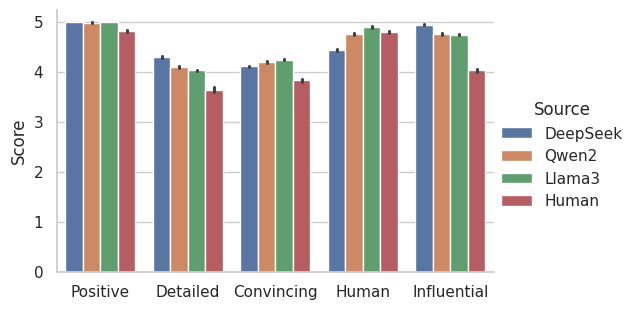

In [11]:
plot_eval(eval_result, figure_name='figure/eval_llm_quality_3llm.pdf')

In [76]:
df_meta[df_meta.parent_asin=='B004SOR4H6']

,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together,subtitle,author
23521,Appstore for Android,Twitter,3.9,38396.0,"['Get more great content, faster.', 'Search sh...","['With Twitter, you can watch the world unfold...",0.0,[{'large': 'https://m.media-amazon.com/images/...,"[{'title': '', 'url': 'https://images-na.ssl-i...",Twitter Inc.,[],"{'Release Date': '2011', 'Date first listed on...",B004SOR4H6,NaN,NaN,NaN
